# Climate Change Patterns: Analyzing Temperature Trends in Michigan and the United States

## Project Description

This project analyzes historical weather observations from NOAA's Global Historical Climatology Network Daily (GHCN-Daily) dataset to investigate long-term temperature trends and potential patterns associated with climate change. Using Python, Pandas, Matplotlib, and scikit-learn, the analysis will focus on changes in average annual temperatures, the frequency of extreme-heat days, and differences in temperature patterns across selected weather stations in Michigan and other U.S. states.

The project will also examine missing values, clean and prepare the data, and use statistical analysis and visualizations to identify trends over time. Finally, a regression model may be used to explore whether historical temperature patterns can help estimate future temperatures. The goal is to better understand how temperature patterns have changed over time and what these trends may suggest about future climate conditions.

## Important: Before Running the Notebook

**If you have already downloaded the filtered dataset files, do not run the code cell that filters the original NOAA files (Cells 2 and 3).** That step is only necessary if you are starting with the original, unfiltered NOAA data.

The filtered data will be provided to download as a zip file.

The original unfiltered NOAA data can be found here: [NOAA Raw Data](https://www.ncei.noaa.gov/pub/data/ghcn/daily/by_year/)

Before running the notebook, make sure you:

1. Download the filtered CSV files.
2. Place all the filtered CSV files inside a folder on your computer.
3. Update the file directory in the data-loading code (4th Code Cell) to match where you saved your files.
4. Run the first cell block conatining all the import statements. If your data is not located in your google drive, you do not need to mount the drive.

Once you have completed these steps, you can run the remaining notebook cells.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Comment these 2 lines of code if you do not need to mount your google drive to access the data
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


## Data Wrangling



*   Data Cleaning
*   Handling of missing values and outliers
*   Type conversions
*   Feature Creation






In [3]:
# DO NOT RUN IF YOU ALREADY HAVE THE FILTERED FILES DOWNLOADED
# If you have the raw NOAA files, change the input_folder and output_folder variables to the locations of the files on your device and run this cell.



# Five selected Michigan weather stations
selected_stations = {
    "USW00094847",  # Detroit Metro Airport
    "USW00014826",  # Flint
    "USW00094860",  # Grand Rapids
    "USW00014836",  # Lansing
    "USW00014850"   # Traverse City
}

# NOAA daily data columns
columns = [
    "station_id",
    "date",
    "element",
    "value",
    "measurement_flag",
    "quality_flag",
    "source_flag",
    "time_flag"
]

# Folders for downloaded and filtered data
input_folder = "/content/drive/MyDrive/CSI 2810/CSI2810_ClimateChangeProject/data/noaa"
output_folder = "/content/drive/MyDrive/CSI 2810/CSI2810_ClimateChangeProject/data/filtered"

os.makedirs(output_folder, exist_ok=True)

files = sorted(glob.glob(os.path.join(input_folder, "*.csv.gz")))

if not files:
    raise FileNotFoundError(
        f"No .csv.gz files found in '{input_folder}'. "
        "Check your folder location."
    )

print(f"Found {len(files)} yearly files.")

Found 11 yearly files.


In [ ]:
# DO NOT RUN IF YOU ALREADY HAVE THE FILTERED FILES DOWNLOADED
# Run this cell only if you have already ran cell 2.

# Filter files by reading the data in chunks to prevent overload
for file in files:
    year = os.path.basename(file).split(".")[0]
    output_file = os.path.join(output_folder, f"{year}.csv")

    # Remove an old output file so rerunning doesn't duplicate data
    if os.path.exists(output_file):
        os.remove(output_file)

    first_chunk = True

    for chunk in pd.read_csv(
        file,
        header=None,
        names=columns,
        chunksize=100_000,
        dtype={
            "station_id": "string",
            "element": "string",
            "value": "Int64",
            "quality_flag": "string"
        }
    ):
        # Keep selected Michigan stations and temperature measurements
        chunk = chunk[
            chunk["station_id"].isin(selected_stations) &
            chunk["element"].isin(["TMAX", "TMIN"])
        ]

        # Keep the columns needed for analysis
        chunk = chunk[
            [
                "station_id",
                "date",
                "element",
                "value",
                "quality_flag"
            ]
        ]

        # Append filtered data to the yearly output file
        if not chunk.empty:
            chunk.to_csv(
                output_file,
                mode="w" if first_chunk else "a",
                header=first_chunk,
                index=False
            )
            first_chunk = False

    if first_chunk:
        print(f"No matching temperature records found for {year}.")
    else:
        print(f"Saved filtered data for {year}.")

    gc.collect()

print("Finished filtering all yearly files.")

In [4]:
print("Filtering completed. All filtered CSV files are saved in data/filtered/.")

Filtering completed. All filtered CSV files are saved in data/filtered/.


In [5]:
# RUN THIS CODE CELL TO READ DATA. CHANGE THE FILE PATH FOR "output_folder" VARIABLE TO THE PATH ON YOUR DEVICE
# WHERE THE FILTERED DATASETS ARE LOCATED


output_folder = "/content/drive/MyDrive/CSI 2810/CSI2810_ClimateChangeProject/data/filtered"

filtered_files = sorted(
    glob.glob(os.path.join(output_folder, "*.csv"))
)


if not filtered_files:
    raise FileNotFoundError(
        "No filtered CSV files found. Check that your folder path is correct."
    )

climate = pd.concat(
    [pd.read_csv(file) for file in filtered_files],
    ignore_index=True
)

print("Dataset shape:", climate.shape)
display(climate.head())

Dataset shape: (39241, 5)


,station_id,date,element,value,quality_flag
0,USW00094847,20160101,TMAX,0,NaN
1,USW00094847,20160101,TMIN,-27,NaN
2,USW00094860,20160101,TMAX,-10,NaN
3,USW00094860,20160101,TMIN,-43,NaN
4,USW00014826,20160101,TMAX,-5,NaN


The date column needs it datatype to be changed to datetime

In [6]:
print("Column data types:\n" ,climate.dtypes)

Column data types:
 station_id      object
date             int64
element         object
value            int64
quality_flag    object
dtype: object


The code below shows that all but 4 rows for the "quality_flag" column are null. This warrants an investigation for the rows that have flags to see if they are acceptable or need to be excluded from the analysis.

In [7]:
print("Missing values:", climate.isna().sum())

Missing values: station_id          0
date                0
element             0
value               0
quality_flag    39237
dtype: int64


For all 4 rows with non-null quality_flags, the value in the column is 'S'. NOAA defines S in the quality flag column as a failure of the spatial consistency check. That means the observation was inconsistent with nearby stations' observations and warrants review. It does not necessarily mean the temperature is incorrect. However, I will exclude these observations from the primary analysis to reduce the risk of questionable measurements affecting the temperature trends, while retaining the original dataset for reference.

In [8]:
flagged_rows = climate[
    climate["quality_flag"].notna() &
    (climate["quality_flag"].astype(str).str.strip() != "")
]

display(
    flagged_rows[
        ["station_id", "date", "element", "value", "quality_flag"]
    ]
)

,station_id,date,element,value,quality_flag
24694,USW00014850,20221005,TMIN,-82,S
30644,USW00014850,20240522,TMIN,11,S
33009,USW00014836,20250114,TMAX,111,S
33077,USW00014836,20250121,TMAX,150,S


In [9]:
# Keep a copy of the original data
climate_original = climate.copy()

# Exclude observations with nonblank quality flags
climate_clean = climate[
    climate["quality_flag"].isna() |
    (climate["quality_flag"].astype(str).str.strip() == "")
].copy()

print("Rows before:", len(climate_original))
print("Rows after:", len(climate_clean))
print("Rows excluded:", len(climate_original) - len(climate_clean))

Rows before: 39241
Rows after: 39237
Rows excluded: 4


**Handling Missing Values and Duplicates**

I checked the essential fields (`station_id`, `date`, `element`, and `value`) for missing values and checked the dataset for duplicate rows. Since no missing values were found in the essential fields and no duplicate rows were identified, removing records with `dropna()` or `drop_duplicates()` was unnecessary. I retained the records to avoid removing valid weather observations without a reason.

In [10]:
# Check missing values in essential fields
essential_fields = ["station_id", "date", "element", "value"]

print(climate[essential_fields].isna().sum())

print("\n")

# Check duplicate rows
print("Essential Fields Duplicate rows:", climate.duplicated().sum())

station_id    0
date          0
element       0
value         0
dtype: int64


Essential Fields Duplicate rows: 0


In [11]:
print("Missing temperature values:", climate["value"].isna().sum())

Missing temperature values: 0


In [12]:
print("Duplicate Columns:", climate.duplicated().sum())

Duplicate Columns: 0


We can see from the result below that the 'date' column's datatype was changed to datetime. 4 new columns were added: year, month, temperature-c, and station_location. These columns will help explore the data by year and month, and station location, giving room for categorical analysis.

In [13]:
# Ensure correct data types
climate["date"] = pd.to_datetime(
    climate["date"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

climate["value"] = pd.to_numeric(
    climate["value"], errors="coerce"
)

# Remove records with invalid dates or values
climate = climate.dropna(
    subset=["date", "value"]
).copy()

# Create analysis columns
climate["year"] = climate["date"].dt.year
climate["month"] = climate["date"].dt.month
climate["temperature_c"] = climate["value"] / 10

# Map station IDs to locations
station_names = {
    "USW00094847": "Detroit",
    "USW00014826": "Flint",
    "USW00094860": "Grand Rapids",
    "USW00014836": "Lansing",
    "USW00014850": "Traverse City"
}

climate["station_location"] = climate["station_id"].map(station_names)

# Add a new season column
conditions = [
    climate["date"].dt.month.isin([12, 1, 2]),
    climate["date"].dt.month.isin([3, 4, 5]),
    climate["date"].dt.month.isin([6, 7, 8]),
    climate["date"].dt.month.isin([9, 10, 11])
]

seasons = ["Winter", "Spring", "Summer", "Fall"]

climate["season"] = np.select(
    conditions,
    seasons,
    default="Unknown"
)

print(climate.dtypes)
display(climate.head())



station_id                  object
date                datetime64[ns]
element                     object
value                        int64
quality_flag                object
year                         int32
month                        int32
temperature_c              float64
station_location            object
season                      object
dtype: object


,station_id,date,element,value,quality_flag,year,month,temperature_c,station_location,season
0,USW00094847,2016-01-01,TMAX,0,NaN,2016,1,0.0,Detroit,Winter
1,USW00094847,2016-01-01,TMIN,-27,NaN,2016,1,-2.7,Detroit,Winter
2,USW00094860,2016-01-01,TMAX,-10,NaN,2016,1,-1.0,Grand Rapids,Winter
3,USW00094860,2016-01-01,TMIN,-43,NaN,2016,1,-4.3,Grand Rapids,Winter
4,USW00014826,2016-01-01,TMAX,-5,NaN,2016,1,-0.5,Flint,Winter


In [14]:
print("Missing temperatures:", climate["temperature_c"].isna().sum())

Missing temperatures: 0


Since I'm analyzing five stations and both TMAX and TMIN I could expect approximately

- 5 stations × 365 days = 1,825 daily records for one temperature type.
- 5 stations × 365 days × 2 temperature types = 3,650 records total.

Actual counts may be lower because of missing observations.
So, I am checking the number of records total for each year to see if any year is incomplete. 2026 only has 2720 records because the year has not completed yet.

I also checked total records based of station location and TMAX,TMIN to see if there are any stations or temperature records that are incomplete. Since everything was in order, I can explore the data.

In [15]:
print(climate.groupby("year").size())

year
2016    3660
2017    3650
2018    3650
2019    3645
2020    3660
2021    3650
2022    3650
2023    3650
2024    3660
2025    3646
2026    2720
dtype: int64


In [16]:
print(
    climate.groupby(["year", "station_location"])
    .size()
    .unstack(fill_value=0)
)

station_location  Detroit  Flint  Grand Rapids  Lansing  Traverse City
year                                                                  
2016                  732    732           732      732            732
2017                  730    730           730      730            730
2018                  730    730           730      730            730
2019                  730    730           730      727            728
2020                  732    732           732      732            732
2021                  730    730           730      730            730
2022                  730    730           730      730            730
2023                  730    730           730      730            730
2024                  732    732           732      732            732
2025                  730    730           730      726            730
2026                  544    544           544      544            544


In [17]:
print(
    climate.groupby(["year", "element"])
    .size()
    .unstack(fill_value=0)
)

element  TMAX  TMIN
year               
2016     1830  1830
2017     1825  1825
2018     1825  1825
2019     1823  1822
2020     1830  1830
2021     1825  1825
2022     1825  1825
2023     1825  1825
2024     1830  1830
2025     1823  1823
2026     1360  1360


**Outlier Detection and Treatment**

I used the interquartile range (IQR) method to identify 17 potential temperature outliers. These observations had temperatures between −20°C and −32°C. Since such temperatures are plausible during Michigan winters, I did not automatically remove them. Instead, I retained the observations to preserve potentially valid extreme weather events and avoid introducing bias into the analysis. I also considered the NOAA quality flags when assessing data reliability. Since none of these records have flags on them, it means there are no inconsistencies with the measurements.

In [18]:
# Calculate IQR boundaries for each station and element
def find_outliers(group):
    q1 = group["temperature_c"].quantile(0.25)
    q3 = group["temperature_c"].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return group[
        (group["temperature_c"] < lower) |
        (group["temperature_c"] > upper)
    ]

outliers = (
    climate.groupby(["station_id", "element"], group_keys=False)
    .apply(find_outliers)
)

print("Potential outlier observations:", len(outliers))
display(
    outliers[
        ["station_id", "date", "element", "temperature_c"]
    ].sort_values("temperature_c")
)

Potential outlier observations: 17


/tmp/ipykernel_1648/3139893351.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(find_outliers)


,station_id,date,element,temperature_c
36756,USW00014826,2026-01-24,TMIN,-31.1
36754,USW00094860,2026-01-24,TMIN,-28.3
18740,USW00014826,2021-02-17,TMIN,-27.7
7275,USW00014826,2017-12-28,TMIN,-27.7
36746,USW00014826,2026-01-23,TMIN,-27.2
36758,USW00014836,2026-01-24,TMIN,-26.7
36816,USW00014826,2026-01-30,TMIN,-26.7
7365,USW00014826,2018-01-06,TMIN,-25.5
11167,USW00014836,2019-01-21,TMIN,-25.5
22200,USW00014826,2022-01-29,TMIN,-25.5


### Challenges faced in preparing the data and how they were resolved.

The first challenge was to read hundreds and thousands of rows for each year. I first tried to read all the rows in each year for all years 2016-2026, which included stations from all over the USA and the world, but I ran into a problem of not enough RAM. So, I decided to pivot my analysis to few major Michigan stations. I chose stations in Lansing, Deroit Metro Airport, Flint, Grand Rapids, Traverse City. I tried to pick stations in different regions of Michigan to get a variety of data. I then filtered each csv file and chose only the stations selected and stored them in a newly created 'filtered' file in my project directory. Finally, I read those filtered files with no errors.

Next was data wrangling, which did not pose many challenges. I checked the datatypes for the columns and checked for missing or duplicate values. I noticed that the date column was not a datetime datatype, so I changed its datatype to datetime. In terms of Outliers, I calculated them using IQR boundaries.

I found that the 'quality_flags' column had many empty rows except 4 rows with 'S' written for that column. I investigated it and found that NOAA defines S as a spatial consistency check. I decided to exclude these rows to reduce the risk of questionable measurements.

## Exploratory Data Analysis (EDA)

Exploratory Questions:

1.   How have average annual temperatures changed over time?
2.   Have extremely hot days become more frequent?
3.    Do different locations in Michigan show different warming patterns?
4. How do average temperatures differ across the four seasons?
5. Are minimum temperatures increasing at a different rate than maximum temperatures?



**Question 1**: How have average annual temperatures changed over time? (Line Chart)

Create a pivot table containing daily average temperatures for more accurate average temperature calculations

In [19]:
# Keep only maximum and minimum temperature records
temp_data = climate[
    climate["element"].isin(["TMAX", "TMIN"])
].copy()

# Pivot TMAX and TMIN into separate columns
daily_temps = temp_data.pivot_table(
    index=["station_id", "station_location", "date", "year", "season"],
    columns="element",
    values="value",
    aggfunc="mean"
).reset_index()

daily_temps.columns.name = None

display(daily_temps.head())

,station_id,station_location,date,year,season,TMAX,TMIN
0,USW00014826,Flint,2016-01-01,2016,Winter,-5.0,-27.0
1,USW00014826,Flint,2016-01-02,2016,Winter,28.0,-16.0
2,USW00014826,Flint,2016-01-03,2016,Winter,22.0,-32.0
3,USW00014826,Flint,2016-01-04,2016,Winter,-27.0,-132.0
4,USW00014826,Flint,2016-01-05,2016,Winter,-5.0,-149.0


In [20]:
# Calculate daily average in Celsius
daily_temps["daily_avg_temp"] = (
    (daily_temps["TMAX"] + daily_temps["TMIN"]) / 2
) / 10

In [21]:
daily_temps = daily_temps.dropna(
    subset=["TMAX", "TMIN"]
).copy()

year
2016    10.686721
2017    10.072411
2018     9.558082
2019     9.011807
2020    10.169126
2021    10.634082
2022     9.616110
2023    10.615534
2024    11.256284
2025     9.570598
2026    11.285441
Name: daily_avg_temp, dtype: float64
Number of years: 11


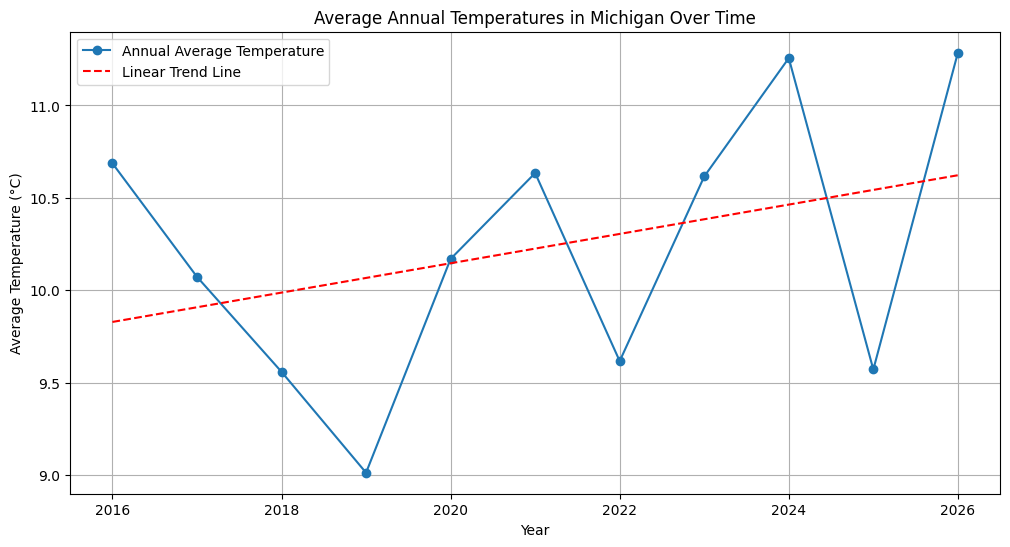

In [22]:
# Calculate average daily temperature for each year
annual_avg_temp = (
    daily_temps.groupby("year")["daily_avg_temp"]
    .mean()
)

print(annual_avg_temp)
print("Number of years:", len(annual_avg_temp))

# Calculate the linear trend line
trend = np.polyfit(
    annual_avg_temp.index,
    annual_avg_temp.values,
    1
)

trend_line = np.poly1d(trend)

# Plot annual temperatures
plt.figure(figsize=(12, 6))

plt.plot(
    annual_avg_temp.index,
    annual_avg_temp.values,
    marker="o",
    label="Annual Average Temperature"
)

# Plot trend line
plt.plot(
    annual_avg_temp.index,
    trend_line(annual_avg_temp.index),
    linestyle="--",
    color="red",
    label="Linear Trend Line"
)

plt.title("Average Annual Temperatures in Michigan Over Time")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.grid(True)
plt.legend()
plt.show()

The chart shows that Michigan's average annual temperatures across 5 stations fluctuated considerably between 2016 and 2025. Temperatures generally declined from 2016 to 2019, followed by an increase through 2021. From 2022 onward, temperatures continued to fluctuate, with warmer averages in 2023 and 2024 and a decline in 2025. Overall, the data shows noticeable year-to-year variation rather than a consistent upward trend. This suggests that, although some years were warmer than others, the selected time period does not establish a clear long-term warming pattern. In the future, a longer range of data should be used to identify long-term warming pattern.

Note: 2026 has been excluded from this interpretation due to it being incomplete.

**Question 2:** Have extremely hot days become more frequent?

In [23]:
# Keep only daily maximum temperatures from complete years
tmax = climate[
    (climate["element"] == "TMAX") &
    (climate["year"] <= 2025)
].copy()

# Identify extremely hot days (90°F or higher)
hot_days = tmax[tmax["temperature_c"] >= 32.2]

# Count hot days for each station and year
hot_day_counts = (
    hot_days.groupby(["year", "station_location"])
    .size()
    .unstack(fill_value=0)
)

# Calculate average number of hot days across stations
annual_hot_days = hot_day_counts.mean(axis=1)

print(annual_hot_days)

year
2016    22.0
2017     9.2
2018    18.4
2019     7.6
2020    17.6
2021     9.2
2022    13.0
2023     8.2
2024     8.4
2025    13.0
dtype: float64


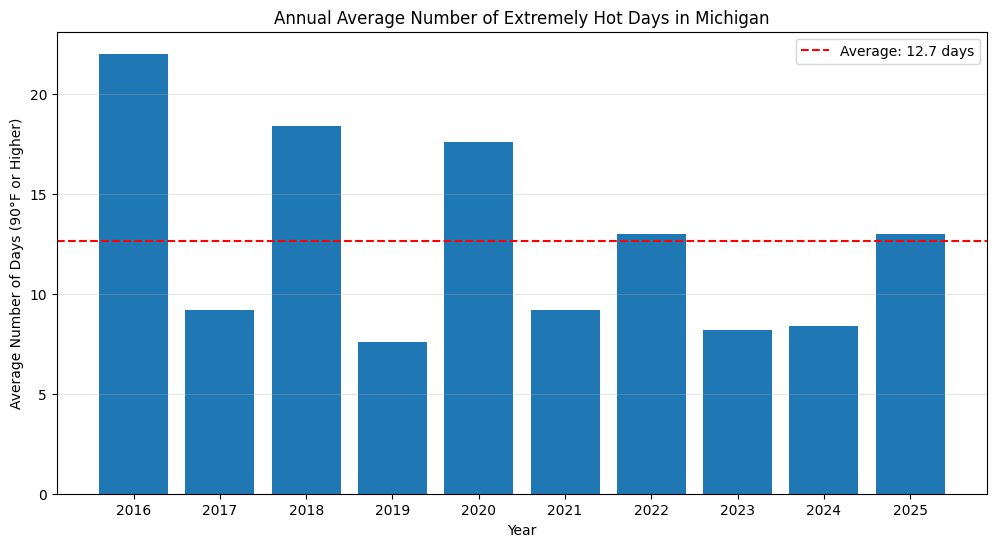

In [24]:
# Calculate average number of extremely hot days
average_hot_days = annual_hot_days.mean()

plt.figure(figsize=(12, 6))

plt.bar(annual_hot_days.index, annual_hot_days.values)

# Add average reference line
plt.axhline(
    y=average_hot_days,
    color="red",
    linestyle="--",
    label=f"Average: {average_hot_days:.1f} days"
)

plt.title("Annual Average Number of Extremely Hot Days in Michigan")
plt.xlabel("Year")
plt.ylabel("Average Number of Days (90°F or Higher)")
plt.xticks(annual_hot_days.index)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.show()

The bar chart shows that the number of extremely hot days (90°F or higher) in Michigan fluctuated considerably between 2016 and 2025. The highest number occurred in 2016, with approximately 22 days, followed by 2018 and 2020, which also experienced relatively high numbers of extremely hot days. In contrast, 2019 had the fewest, with approximately 7.6 days. The red dashed line represents the overall average of 12.7 days per year. Only 2016, 2018, 2020, 2022, and 2025 were at or above this average. Overall, the chart does not show a consistent increase in extremely hot days over the selected period; instead, it demonstrates significant year-to-year variation.

**Question 3**: Do different locations in Michigan show different warming patterns?

In [25]:
# Exclude incomplete 2026 data
complete_years = daily_temps[daily_temps["year"] <= 2025]

# Calculate average temperature for each station by year
station_temps = complete_years.groupby(
    ["year", "station_location"]
)["daily_avg_temp"].mean().unstack()

print(station_temps)

station_location    Detroit      Flint  Grand Rapids    Lansing  Traverse City
year                                                                          
2016              11.638661  10.882514     10.727459  10.401366       9.783607
2017              11.351918   9.577123     10.220822  10.261233       8.950959
2018              10.846986   8.906164      9.876712   9.472466       8.688082
2019              10.350411   9.091918      9.235479   8.863950       7.511951
2020              11.100683  10.431421     10.133743   9.963251       9.216530
2021              11.541644  10.526164     10.548356  10.707671       9.846575
2022              10.688493   9.216301      9.400411  10.036575       8.738767
2023              11.454521  10.256438     10.609041  10.760274       9.997397
2024              12.263525  11.086749     11.258060  11.000820      10.672268
2025              10.627671   9.258493      9.739452   9.674380       8.553562


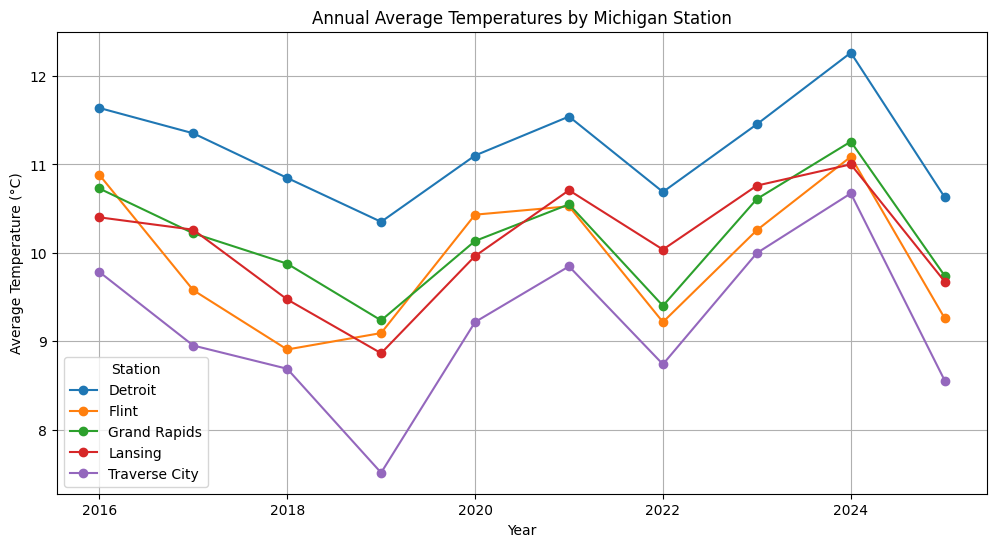

In [26]:
plt.figure(figsize=(12, 6))

# Plot a separate line for each station
for station in station_temps.columns:
    plt.plot(
        station_temps.index,
        station_temps[station],
        marker="o",
        label=station
    )

plt.title("Annual Average Temperatures by Michigan Station")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.grid(True)
plt.legend(title="Station")
plt.show()

The line chart shows annual average temperatures for five Michigan stations from 2016 to 2025. Traverse City is consistently the coldest, while Detroit is consistently the warmest. This is consistent with a north-south gradient, though factors like Lake Michigan proximity and Detroit’s urban setting may also play a role. Flint, Lansing, and Grand Rapids fall in the middle and are broadly similar, though Flint varies more from year to year. All stations follow the same yearly pattern, with lows in 2019 and 2022, a peak in 2024, and a sharp drop in 2025, suggesting regional weather conditions drive year-to-year changes. The 2025 drop should be verified, since it may reflect incomplete data.

**Question 4**: How do average temperatures differ across the four seasons?

In [27]:
season_order = ["Winter", "Spring", "Summer", "Fall"]

season_avg_temp = (
    daily_temps.groupby("season")["daily_avg_temp"]
    .mean()
    .reindex(season_order)
)

print(season_avg_temp)

season
Winter    -2.014569
Spring     8.747460
Summer    21.838335
Fall      11.739250
Name: daily_avg_temp, dtype: float64


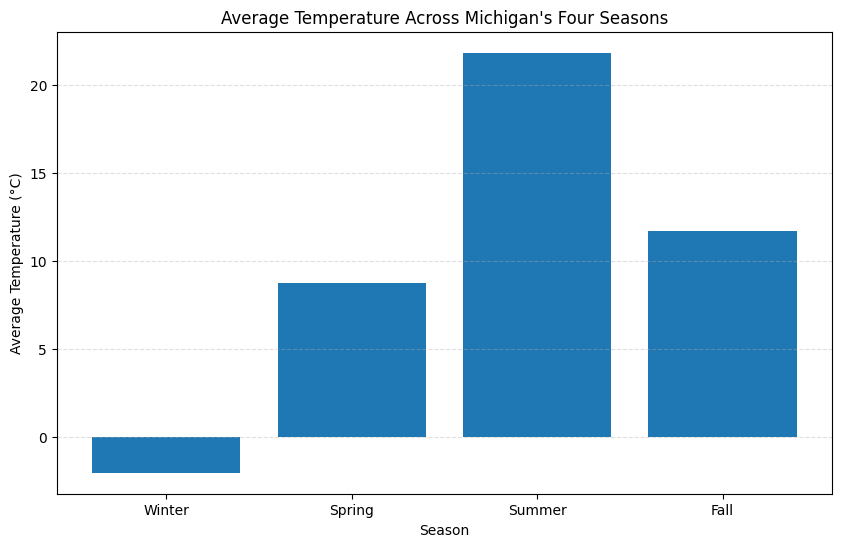

In [28]:
plt.figure(figsize=(10, 6))

plt.bar(season_avg_temp.index, season_avg_temp.values)

plt.title("Average Temperature Across Michigan's Four Seasons")
plt.xlabel("Season")
plt.ylabel("Average Temperature (°C)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

This chart shows average temperatures across Michigan’s four seasons. Winter is the coldest season at about -2°C and the only one with an average below freezing, while summer is the warmest at about 21.8°C, a seasonal swing of roughly 24°C. Fall (about 11.7°C) is warmer than spring (about 8.8°C), which may reflect the Great Lakes retaining summer heat into the fall and staying cold into the spring.

**Question 5** Are minimum temperatures increasing at a different rate than maximum temperatures?

In [29]:
# Exclude incomplete 2026 data
complete_years = climate[climate["year"] <= 2025]

# Calculate annual average maximum and minimum temperatures
annual_extremes = (
    complete_years.groupby(["year", "element"])["temperature_c"]
    .mean()
    .unstack()
)

print(annual_extremes)

element       TMAX      TMIN
year                        
2016     15.765574  5.607869
2017     15.159233  4.985589
2018     14.342301  4.773863
2019     13.912342  4.130351
2020     15.167705  5.170546
2021     15.701863  5.566301
2022     14.802575  4.429644
2023     15.553589  5.677479
2024     16.367705  6.144863
2025     14.913878  4.227318


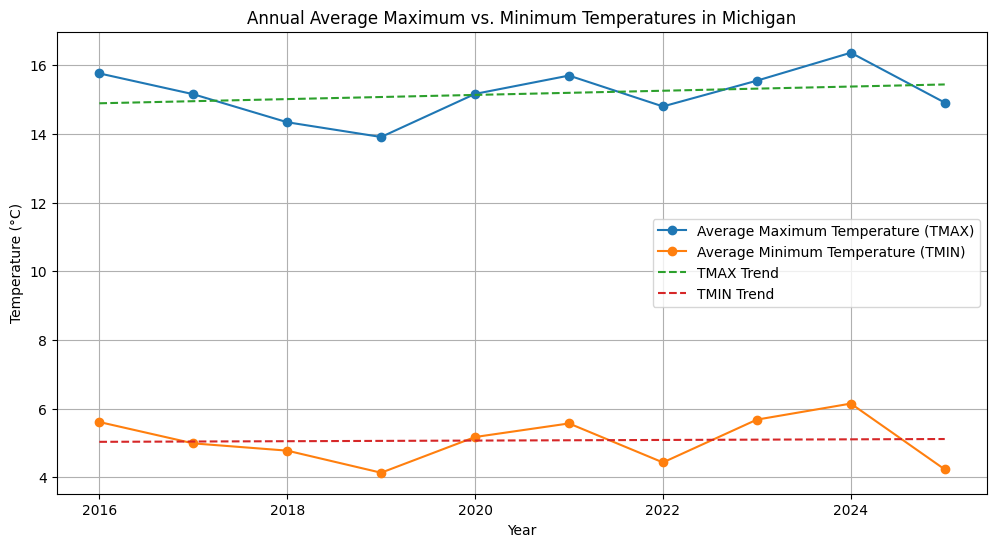

In [30]:
plt.figure(figsize=(12, 6))

# Plot maximum temperatures
plt.plot(
    annual_extremes.index,
    annual_extremes["TMAX"],
    marker="o",
    label="Average Maximum Temperature (TMAX)"
)

# Plot minimum temperatures
plt.plot(
    annual_extremes.index,
    annual_extremes["TMIN"],
    marker="o",
    label="Average Minimum Temperature (TMIN)"
)

# Calculate trend lines
max_trend = np.polyfit(
    annual_extremes.index,
    annual_extremes["TMAX"],
    1
)

min_trend = np.polyfit(
    annual_extremes.index,
    annual_extremes["TMIN"],
    1
)

# Convert coefficients into trend functions
max_line = np.poly1d(max_trend)
min_line = np.poly1d(min_trend)

# Plot trend lines
plt.plot(
    annual_extremes.index,
    max_line(annual_extremes.index),
    linestyle="--",
    label="TMAX Trend"
)

plt.plot(
    annual_extremes.index,
    min_line(annual_extremes.index),
    linestyle="--",
    label="TMIN Trend"
)

plt.title("Annual Average Maximum vs. Minimum Temperatures in Michigan")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()

plt.show()

In [31]:
print(f"TMAX warming rate: {max_trend[0]:.4f} °C per year")
print(f"TMIN warming rate: {min_trend[0]:.4f} °C per year")

TMAX warming rate: 0.0609 °C per year
TMIN warming rate: 0.0091 °C per year


This chart compares annual average maximum (TMAX) and minimum (TMIN) temperatures in Michigan from 2016 to 2025. Daytime highs average roughly 14-16°C, while nighttime lows average roughly 4-6°C, a consistent gap of about 10°C. Both series move together from year to year, with lows in 2019 and peaks in 2024, and both drop sharply in 2025. Linear trend lines show a slight upward slope for both, with TMAX rising about 0.061°C per year and TMIN about 0.009°C per year. Over the decade, that works out to roughly 0.6°C of warming in highs and almost none in lows. However, with only ten years of data and large year-to-year swings, these trends are small relative to the natural variability and should not be treated as evidence of long-term warming.

## Preliminary Modeling Approach

### Model Goal

The goal of this project is to use time-series analysis to examine historical temperature patterns in Michigan and identify whether average temperatures, maximum temperatures, and minimum temperatures have changed over time. The analysis focuses on identifying long-term trends and comparing temperature changes across different years and locations.

### Models Explored and Rationale

**Linear Regression**

Linear regression was selected to identify the overall direction and rate of temperature change over time. By fitting a trend line to annual average temperatures, the model helps determine whether temperatures are generally increasing or decreasing.

Separate linear regression models are also used to compare maximum (TMAX) and minimum (TMIN) temperature trends. This helps determine whether nighttime minimum temperatures are increasing at a different rate than daytime maximum temperatures.

### Initial Model Setup and Evaluation

In [32]:
# Prepare the data
X = annual_extremes.index.values.reshape(-1, 1)
y_max = annual_extremes["TMAX"].values
y_min = annual_extremes["TMIN"].values

# Initialize models
max_model = LinearRegression()
min_model = LinearRegression()

# Train models
max_model.fit(X, y_max)
min_model.fit(X, y_min)

# Generate predictions
max_predictions = max_model.predict(X)
min_predictions = min_model.predict(X)

# Evaluate models
print("TMAX R²:", r2_score(y_max, max_predictions))
print("TMIN R²:", r2_score(y_min, min_predictions))

print("TMAX MSE:", mean_squared_error(y_max, max_predictions))
print("TMIN MSE:", mean_squared_error(y_min, min_predictions))

# Display warming rates
print("TMAX trend:", max_model.coef_[0] * 10, "°C per decade")
print("TMIN trend:", min_model.coef_[0] * 10, "°C per decade")

TMAX R²: 0.06537490103268284
TMIN R²: 0.0016394924700977587
TMAX MSE: 0.4380321342366525
TMIN MSE: 0.4161169313043633
TMAX trend: 0.6094145430097937 °C per decade
TMIN trend: 0.0910105493602592 °C per decade


Evaluation metrics:
- R² (R-squared): Measures how much of the variation in annual temperatures is explained by the linear trend.
- MSE (Mean Squared Error): Measures the average squared difference between actual and predicted temperatures.
- Regression coefficient: Represents the estimated temperature change per year. Multiplying it by 10 gives the estimated change per decade.

### Next Steps for Model Improvement

- Compare the temperature trends between the five Michigan weather stations to see if some areas are warming faster than others.



- Look more closely at whether minimum temperatures are rising faster than maximum temperatures.



- Try polynomial regression to see if temperature changes follow a curved pattern instead of a straight line.



- Test the models using data they haven't been trained on to see how well they perform.



- Add more years of historical temperature data to get a better picture of long-term temperature changes.